In [1]:
import scanpy as sc
from scipy import sparse
import pandas as pd
import scarches as sca
import os

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:lightning_fabric.utilities.seed:[rank: 0] Global seed set to 0
 captum (see https://github.com/pytorch/captum).


In [2]:
ref_model_dir = "./HLCA_reference_model"

In [3]:
query_prefix = "/lustre/groups/ml01/workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/HLCA_extended/extension_datasets/ready/subsetted/"

In [4]:
query_paths = {"Thienpont_2018_10Xv2":"lambrechts_sub.h5ad"}

In [5]:
query_batch = "Thienpont_2018_10Xv2"

In [6]:
max_kl_weight = 1

In [7]:
surgery_model_dir = f"./{query_batch}_kl{max_kl_weight}_sample_as_batch"
if not os.path.isdir(surgery_model_dir):
    print("Creating directory", surgery_model_dir)
    os.makedirs(surgery_model_dir)

Creating directory ./Thienpont_2018_10Xv2_kl1_sample_as_batch


### Load and prep reference:

In [8]:
adata_ref = sc.read_h5ad("../../../data/HLCA_full_v1.1_emb.h5ad")

In [10]:
# subset
adata_ref = adata_ref[adata_ref.obs.core_or_extension == "core", :].copy()
# remove all obs variables that have no entries anymore (i.e. obs columns that were only relevant for the HLCA extension)
cols_to_drop = [
    col for col in adata_ref.obs.columns if adata_ref.obs[col].isnull().all()
]
adata_ref.obs.drop(columns=cols_to_drop, inplace=True)

In [11]:
adata_ref.shape

(584944, 30)

### Load and prep query:

In [12]:
adata_query_unprep = sc.read_h5ad(query_prefix + query_paths[query_batch])

In [32]:
adata_query_unprep.obs['lung_condition'] = "Healthy (tumor adjacent)"
adata_query_unprep.obs.loc[adata_query_unprep.obs.cell_from_tumor, "lung_condition"] = "Tumor"

In [33]:
adata_query_unprep.X = sparse.csr_matrix(adata_query_unprep.X)
del adata_query_unprep.obsm
del adata_query_unprep.varm

In [34]:
adata_query_unprep.X[:10,:10].toarray()

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 2., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [35]:
ref_model_features = pd.read_csv(
    (f"{ref_model_dir}/var_names.csv"), header=None
)

In [36]:
adata_query_unprep.var.head(5)

,original_gene_names,gene_symbols,ensembl,gene_symbol
ensembl,,,,
ENSG00000000938,FGR,nan,ENSG00000000938,FGR
ENSG00000000971,CFH,nan,ENSG00000000971,CFH
ENSG00000002587,HS3ST1,nan,ENSG00000002587,HS3ST1
ENSG00000002933,TMEM176A,nan,ENSG00000002933,TMEM176A
ENSG00000003436,TFPI,nan,ENSG00000003436,TFPI


In [18]:
ref_model_features.head(5)

,0
0,ENSG00000000938
1,ENSG00000000971
2,ENSG00000002587
3,ENSG00000002933
4,ENSG00000003436


In [19]:
(adata_query_unprep.var.ensembl.isin(ref_model_features[0])).sum()

2000

In [20]:
adata_query_unprep.var['gene_symbol'] = adata_query_unprep.var.index
adata_query_unprep.var.index = adata_query_unprep.var.ensembl

In [21]:
adata_query_unprep.var.head(5)

,original_gene_names,gene_symbols,ensembl,gene_symbol
ensembl,,,,
ENSG00000000938,FGR,nan,ENSG00000000938,FGR
ENSG00000000971,CFH,nan,ENSG00000000971,CFH
ENSG00000002587,HS3ST1,nan,ENSG00000002587,HS3ST1
ENSG00000002933,TMEM176A,nan,ENSG00000002933,TMEM176A
ENSG00000003436,TFPI,nan,ENSG00000003436,TFPI


In [22]:
adata_query_unprep.obs['dataset'] = adata_query_unprep.obs['sample']

In [37]:
adata_query = sca.models.SCANVI.prepare_query_anndata(
    adata=adata_query_unprep, reference_model=ref_model_dir, inplace=False
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   
INFO     Found 100.0% reference vars in query data.                                                                


In [38]:
adata_query.shape

(93575, 2000)

In [39]:
adata_query

AnnData object with n_obs × n_vars = 93575 × 2000
    obs: 'n_genes_detected', 'total_counts', 'cell_from_tumor', 'subject_ID', 'tumor_site', 'original_celltype_ann', 'sample', 'study', 'study_long', 'dataset', 'last_author_PI', 'lung_vs_nasal', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'ann_highest_res', 'ann_new', 'scanvi_label', 'lung_condition'
    var: 'original_gene_names', 'gene_symbols', 'ensembl', 'gene_symbol'

### Load reference model and set relevant query variables:

In [40]:
surgery_model = sca.models.SCANVI.load_query_data(
    adata_query,
    ref_model_dir,
    freeze_dropout=True,
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   


In [41]:
surgery_model.registry_["setup_args"]

{'labels_key': 'scanvi_label',
 'unlabeled_category': 'unlabeled',
 'layer': None,
 'batch_key': 'dataset',
 'size_factor_key': None,
 'categorical_covariate_keys': None,
 'continuous_covariate_keys': None}

In [42]:
adata_query.obs['scanvi_label'] = "unlabeled"

In [43]:
surgery_model = sca.models.SCANVI.load_query_data(
    adata_query,
    ref_model_dir,
    freeze_dropout=True,
)

INFO     File ./HLCA_reference_model/model.pt already downloaded                                                   


## Map:

### perform surgery

In [44]:
surgery_model.train(plan_kwargs={"weight_decay": 0.0, "max_kl_weight":max_kl_weight}, check_val_every_n_epoch=3)

INFO     Training for 85 epochs.                                                                                   


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_ ...
  rank_zero_warn(
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Li

Epoch 85/85: 100%|██████████| 85/85 [13:50<00:00,  9.51s/it, loss=503, v_num=1]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=85` reached.


Epoch 85/85: 100%|██████████| 85/85 [13:50<00:00,  9.77s/it, loss=503, v_num=1]


In [45]:
surgery_model.save(surgery_model_dir, overwrite=True)

load model if starting from here:

In [46]:
# surgery_model = sca.models.SCANVI.load(
#     surgery_model_dir, adata_query
# ) 

### obtain query latent embedding:

In [47]:
adata_query_latent = sc.AnnData(surgery_model.get_latent_representation(adata_query))

In [48]:
adata_query_latent.obs = adata_query.obs.loc[adata_query.obs.index, :]

### combine reference and query embedding into one joint embedding:

In [49]:
adata_query_latent.obs["core_or_extension"] = "extension"

In [50]:
combined_emb = sc.concat(
    (adata_ref, adata_query_latent), index_unique=None, join="outer"
) 

As the data concatenation might have resulted in some mixed dtype obs columns, we will convert those to strings here to prevent writing errors below.

In [51]:
for cat in combined_emb.obs.columns:
    if isinstance(combined_emb.obs[cat].values, pd.Categorical):
        pass
    elif pd.api.types.is_float_dtype(combined_emb.obs[cat]):
        pass
    else:
        print(
            f"Setting obs column {cat} (not categorical neither float) to strings to prevent writing error."
        )
        combined_emb.obs[cat] = combined_emb.obs[cat].astype(str)

Setting obs column is_primary_data (not categorical neither float) to strings to prevent writing error.
Setting obs column ann_level_1 (not categorical neither float) to strings to prevent writing error.
Setting obs column ann_level_2 (not categorical neither float) to strings to prevent writing error.
Setting obs column ann_level_3 (not categorical neither float) to strings to prevent writing error.
Setting obs column ann_level_4 (not categorical neither float) to strings to prevent writing error.
Setting obs column ann_level_5 (not categorical neither float) to strings to prevent writing error.
Setting obs column core_or_extension (not categorical neither float) to strings to prevent writing error.
Setting obs column dataset (not categorical neither float) to strings to prevent writing error.
Setting obs column lung_condition (not categorical neither float) to strings to prevent writing error.
Setting obs column sample (not categorical neither float) to strings to prevent writing err

### neighbor graph + visualization of joint embedding

In [ ]:
sc.pp.neighbors(combined_emb, n_neighbors=30)
sc.tl.umap(combined_emb)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


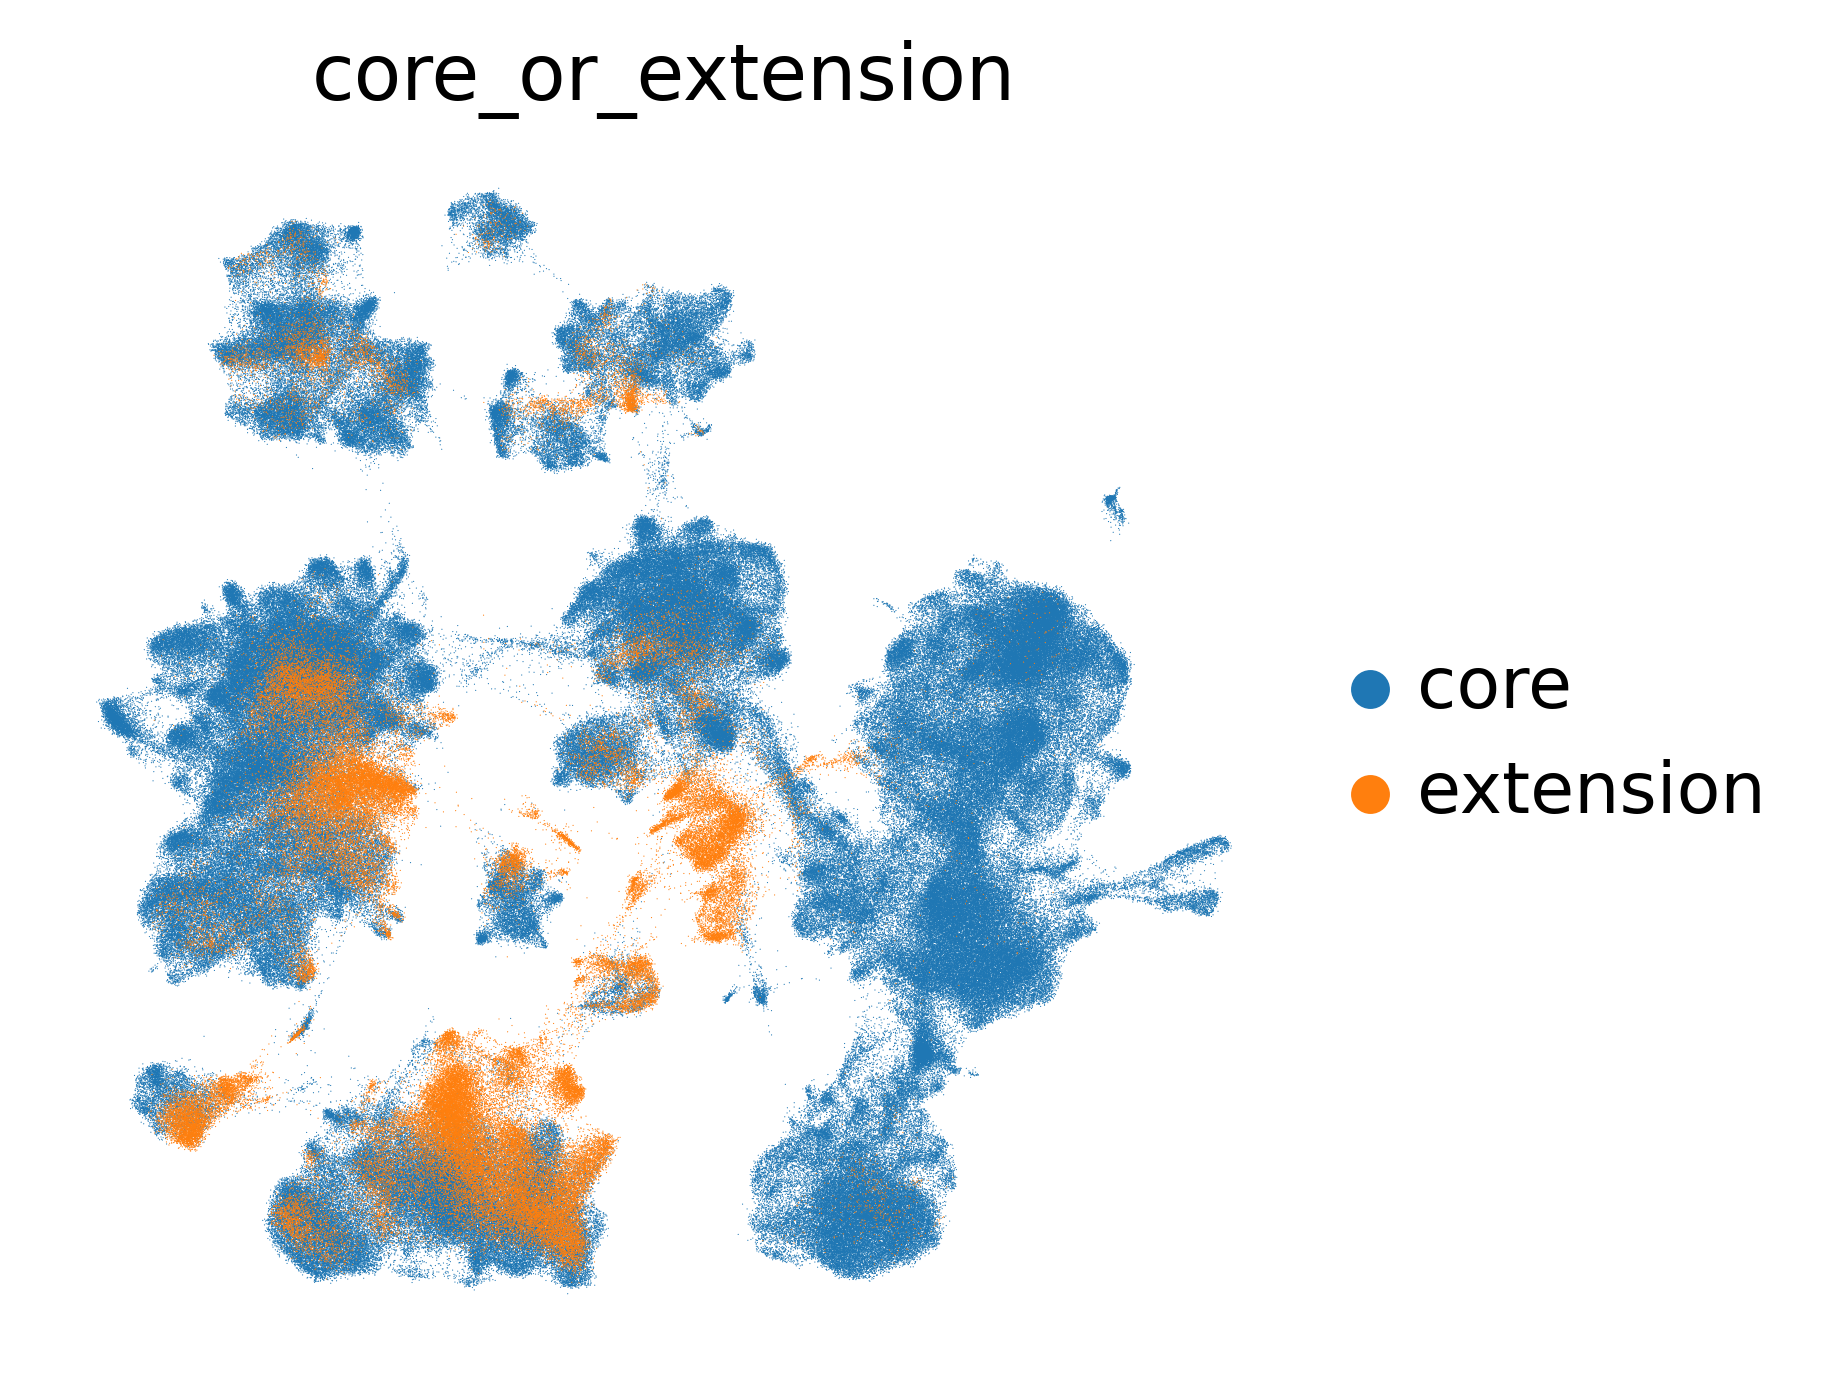

In [55]:
sc.pl.umap(combined_emb, color="core_or_extension", frameon=False, wspace=0.6)

In [ ]:
combined_emb.write_h5ad(os.path.join(surgery_model_dir, f"combined_embedding_klweight_{max_kl_weight}.h5ad"))